<a href="https://colab.research.google.com/github/dennisquispe/Machine-learning-I/blob/main/Lab_Aprendizaje_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sesiones 7 y 8 · Aprendizaje no supervisado y redes neuronales
**Machine Learning · Maestría en Ciencia de Datos e IA · EPG UNAJ** · Dr. Alain Paul Herrera Urtiaga

Donde vean **`# TODO`**, les toca completar. Donde vean ** Predice**, escriban su respuesta *antes* de ejecutar.

 Ejecuten las celdas **en orden, de arriba hacia abajo**. Si Colab se reinicia: *Entorno de ejecución → Ejecutar todas*.

## 0 · Preparación (ya está hecho, solo ejecuten)

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, roc_auc_score
from sklearn.neural_network import MLPClassifier #trabajamos con una red neuronal
from lightgbm import LGBMClassifier
import torch
import torch.nn as nn

def cargar_datos():
    """Descarga el dataset (copia de UCI en GitHub); si no hay internet, lee data.csv."""
    try:
        df = pd.read_csv("https://raw.githubusercontent.com/UBC-MDS-2023-24/Student_Success_Predict_Group15/main/data/raw/data.csv", sep=";")
    except Exception:
        try:
            df = pd.read_csv("data.csv", sep=";")
        except FileNotFoundError:
            raise RuntimeError("No pude descargar los datos ni encontré data.csv. "
                               "Suban data.csv al panel Archivos de Colab.") from None
    df.columns = [c.strip().lower() for c in df.columns]
    nombres = {
        "admission grade": "nota_admision", "scholarship holder": "becado",
        "age at enrollment": "edad", "gender": "genero", "debtor": "deudor",
        "tuition fees up to date": "pension_al_dia",
        "curricular units 1st sem (enrolled)": "inscritos_1er_sem",
        "curricular units 1st sem (evaluations)": "evaluaciones_1er_sem",
        "curricular units 1st sem (approved)": "aprobados_1er_sem",
        "curricular units 1st sem (grade)": "nota_1er_sem",
    }
    df = df.rename(columns=nombres)
    df["abandona"] = (df["target"].str.strip() == "Dropout").astype(int)
    return df[list(nombres.values()) + ["abandona"]]

df = cargar_datos()
variables = [c for c in df.columns if c != "abandona"]
X, y = df[variables], df["abandona"]
print(X.shape, f"abandonan: {y.mean():.0%}")

(4424, 10) abandonan: 32%


---
# Práctica 1 · Perfiles ocultos
Agrupamos a los estudiantes **sin usar la columna `abandona`**. Solo al final la miramos, para ver si los grupos tienen sentido.

### 1a. ¿Cuántos grupos?

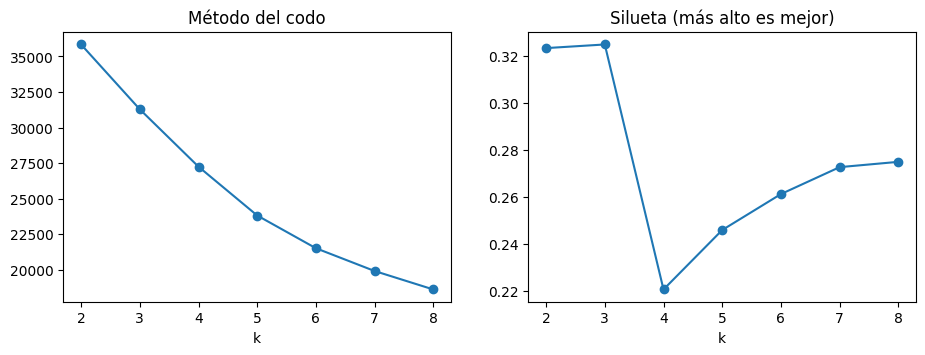

In [ ]:
Z = StandardScaler().fit_transform(X)        # escalar: k-means usa distancias

ks = range(2, 9) #estos son los grupos para probar/ se probara de 2 a 8 grupos
inercias, siluetas = [], []
for k in ks: #recorremos grupo por grupo
    # TODO: entrenen KMeans con n_clusters=k, n_init=10, random_state=42 sobre Z
    km = KMeans(n_clusters=k, n_init=10,random_state=42).fit(Z)
    inercias.append(km.inertia_)#la inercia es la distancia a su centro
    siluetas.append(silhouette_score(Z, km.labels_, sample_size=2000, random_state=42))# siluestas con 200 casos estamos tranbajando

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(ks)[:len(inercias)], inercias, "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k")
ax[1].plot(list(ks)[:len(siluetas)], siluetas, "o-"); ax[1].set_title("Silueta (más alto es mejor)"); ax[1].set_xlabel("k")
plt.show()

**¿Qué k eligen? ¿Por qué?** _____

### 1b. Ponerle nombre a cada grupo
**Predice:** ¿algún grupo tendrá mucho más abandono que los demás?
**Nuestra predicción:** _____

In [4]:
K = 3   # TODO: cambien por el k que eligieron
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
df["grupo"] = km.labels_

# Promedio de cada variable por grupo: así se "lee" cada perfil
perfiles = df.groupby("grupo")[variables].mean().round(1)
perfiles["n_estudiantes"] = df["grupo"].value_counts().sort_index()
perfiles["% abandono"] = (df.groupby("grupo")["abandona"].mean() * 100).round(0)   # recién aquí miramos y
perfiles

,nota_admision,becado,edad,genero,deudor,pension_al_dia,inscritos_1er_sem,evaluaciones_1er_sem,aprobados_1er_sem,nota_1er_sem,n_estudiantes,% abandono
grupo,,,,,,,,,,,,
0,129.6,0.1,29.4,0.4,0.2,0.9,13.1,16.8,11.5,12.6,290,24.0
1,126.8,0.3,22.1,0.3,0.1,0.9,6.1,8.5,5.2,12.7,3370,22.0
2,126.8,0.1,26.1,0.6,0.2,0.7,4.2,4.1,0.1,0.7,764,80.0


**Pónganle nombre a cada grupo** mirando sus promedios (por ejemplo, "regulares", "en riesgo", "mayores que trabajan"):

| Grupo | Nombre | % abandono |
|---|---|---|
| 0 | | |
| 1 | | |
| 2 | | |

Información conservada por las 2 componentes: 46%


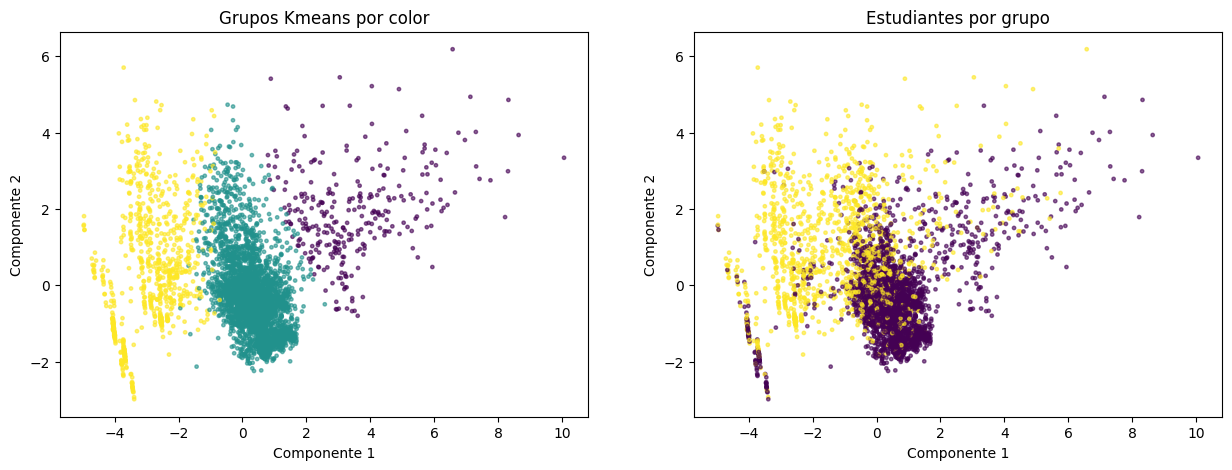

In [9]:
# Mapa de los estudiantes con PCA
pca = PCA(n_components=2).fit(Z)
mapa = pca.transform(Z)
print("Información conservada por las 2 componentes:", f"{pca.explained_variance_ratio_.sum():.0%}")

# TODO: dibujen el mapa coloreado por grupo
fig, ax = plt.subplots(1,2, figsize=(15, 5))
ax[0].scatter(mapa[:, 0], mapa[:, 1], c=df["grupo"], s=6, cmap="viridis", alpha=0.6)# asigna color a l grupo
ax[0].set_title('Grupos Kmeans por color')
ax[1].scatter(mapa[:,0], mapa [:,1], c=df["abandona"], s=6, cmap="viridis", alpha=0.6) #esto es el color de los qque avandonan
ax[1].set_title('Estudiantes por grupo')

for a in ax:
  a.set_xlabel('Componente 1')
  a.set_ylabel('Componente 2')
plt.show()
#ax[1].scatter(mapa[:, 0], mapa[:, 1], c=df["abandona"], s=6, cmap="viridis", alpha=0.6)
#plt.xlabel("Componente 1"); plt.ylabel("Componente 2"); plt.title("Estudiantes por grupo"); plt.show() #

**¿El modelo encontró un perfil de riesgo sin conocer la respuesta? ¿Cómo lo usaría una universidad?** _____

---
# Práctica 2 · Casos raros
**Predice:** los estudiantes "raros", ¿abandonan más o menos que el resto?
**Nuestra predicción:** _____

In [11]:
# TODO: entrenen IsolationForest con contamination=0.03 y random_state=42 sobre Z

iso = IsolationForest(contamination=0.03,
                      random_state=24).fit(Z)
df["raro"] = iso.predict(Z) == -1          # -1 = anómalo / 1=  normal /va predecir de -1 a 1

print(f"Estudiantes raros: {df['raro'].sum()}")
print(df.groupby("raro")["abandona"].mean().rename({False: "resto", True: "raros"}).map("{:.0%}".format))

Estudiantes raros: 133
raro
resto    32%
raros    52%
Name: abandona, dtype: object


In [12]:
# ¿Qué tienen de distinto? Comparamos los promedios de raros y resto
if "raro" not in df:
    print("Primero completen y ejecuten la celda anterior (IsolationForest).")
else:
    comparacion = df.groupby("raro")[variables].mean().T.round(1)
    comparacion.columns = ["resto", "raros"]
    comparacion["diferencia"] = (comparacion["raros"] - comparacion["resto"]).round(1)
    display(comparacion.sort_values("diferencia", key=abs, ascending=False))

,resto,raros,diferencia
edad,23.0,32.0,9.0
nota_admision,126.8,133.9,7.1
evaluaciones_1er_sem,8.2,12.3,4.1
nota_1er_sem,10.7,7.1,-3.6
inscritos_1er_sem,6.2,9.3,3.1
aprobados_1er_sem,4.6,7.3,2.7
pension_al_dia,0.9,0.5,-0.4
deudor,0.1,0.5,0.4
genero,0.3,0.6,0.3
becado,0.2,0.3,0.1


**En una frase: ¿qué hace "raro" a un estudiante?** _____

**Para su proyecto:** ¿qué serían los "casos raros" en sus datos? ¿Errores de digitación, fraude, situaciones especiales?

---
# Práctica 3 · Red vs. ensamble
### 3a. Un MLP en una línea, con scikit-learn
**Predice:** ¿la red le ganará al LightGBM?
**Nuestra predicción:** _____

In [13]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgbm = LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=16, random_state=42, verbose=-1)
s_lgbm = cross_val_score(lgbm, X_tr, y_tr, cv=cv, scoring="roc_auc")
print(f"LightGBM:          AUC = {s_lgbm.mean():.3f} ± {s_lgbm.std():.3f}")

# TODO: un MLP con dos capas ocultas (32 y 16 neuronas), con escalado y early stopping
red_sk = make_pipeline(StandardScaler(),
                       MLPClassifier(hidden_layer_sizes=(32, 16), #estamos usando 2 neuronas una con 32 y otra con 16
                                     early_stopping=True,
                                     max_iter=500, random_state=42))
s_red = cross_val_score(red_sk, X_tr, y_tr, cv=cv, scoring="roc_auc")
print(f"MLP (scikit-learn): AUC = {s_red.mean():.3f} ± {s_red.std():.3f}")

LightGBM:          AUC = 0.886 ± 0.014
MLP (scikit-learn): AUC = 0.878 ± 0.007


### 3b. La misma red, por dentro, con PyTorch
Ahora la armamos nosotros para **ver cómo aprende época por época**.

In [14]:
# Separamos una parte de train para validar, y escalamos (aprendiendo solo con train)
X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=0)
esc = StandardScaler().fit(X_a)
Xa_t = torch.tensor(esc.transform(X_a), dtype=torch.float32)
Xv_t = torch.tensor(esc.transform(X_v), dtype=torch.float32)
ya_t = torch.tensor(y_a.values, dtype=torch.float32)
yv_t = torch.tensor(y_v.values, dtype=torch.float32)

torch.manual_seed(42)
red = nn.Sequential(
    nn.Linear(len(variables), 32), nn.ReLU(), nn.Dropout(0.2),   # capa oculta 1 ingresan 10 variables 10 neuronas
    nn.Linear(32, 16), nn.ReLU(),                                 # capa oculta 2
    nn.Linear(16, 1))  #la salida es una sola neurona                                           # salida (sin sigmoide: la incluye la pérdida)
perdida = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(red.parameters(), lr=0.01)
print(red)

Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=32, out_features=16, bias=True)
  (4): ReLU()
  (5): Linear(in_features=16, out_features=1, bias=True)
)


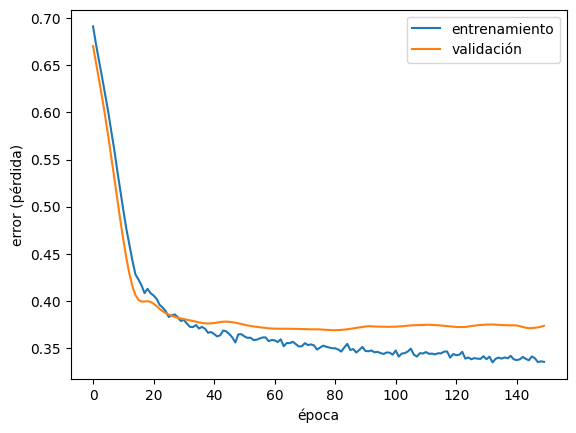

Época con menor error de validación: 79


In [15]:
hist_train, hist_val = [], []
for epoca in range(150):
    red.train()
    # TODO: los 4 pasos del entrenamiento
    opt.zero_grad()                                   # 1. limpiar el ajuste anterior
    error = perdida(red(Xa_t).squeeze(), ya_t)        # 2. predecir y medir el error
    error.backward()                                  # 3. retropropagación
    opt.step()                                        # 4. ajustar los pesos
    hist_train.append(error.item())

    red.eval()
    with torch.no_grad():                               # en validación no se aprende
        hist_val.append(perdida(red(Xv_t).squeeze(), yv_t).item())

plt.plot(hist_train, label="entrenamiento"); plt.plot(hist_val, label="validación")
plt.xlabel("época"); plt.ylabel("error (pérdida)"); plt.legend(); plt.show()
print("Época con menor error de validación:", int(np.argmin(hist_val)))

In [16]:
# AUC de la red de PyTorch en validación, comparado con LightGBM en los mismos datos
red.eval()
with torch.no_grad():
    prob_red = torch.sigmoid(red(Xv_t).squeeze()).numpy()     # la sigmoide convierte en probabilidad
lgbm.fit(X_a, y_a)
prob_lgbm = lgbm.predict_proba(X_v)[:, 1]
print(f"Red PyTorch:  AUC = {roc_auc_score(y_v, prob_red):.3f}")
print(f"LightGBM:     AUC = {roc_auc_score(y_v, prob_lgbm):.3f}")

Red PyTorch:  AUC = 0.888
LightGBM:     AUC = 0.887


**¿En qué época conviene parar? ¿Qué pasa con la curva de validación después de ese punto?** _____

**¿Quién ganó? ¿Qué modelo elegirían para un sistema de alerta real y por qué?** _____

In [ ]:
# TODO: reemplacen X_proy e y_proy por los de su proyecto (solo variables numéricas, sin la respuesta)
# Z_proy = StandardScaler().fit_transform(X_proy)
#
# # 1) Segmentación
# km_proy = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z_proy)
# print("Silueta:", silhouette_score(Z_proy, km_proy.labels_))
#
# # 2) Casos raros
# raros_proy = IsolationForest(contamination=0.03, random_state=42).fit(Z_proy).predict(Z_proy) == -1
#
# # 3) Red contra su mejor modelo
# red_proy = make_pipeline(StandardScaler(),
#                          MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=500, random_state=42))
# print(cross_val_score(red_proy, X_proy, y_proy, cv=5, scoring="roc_auc").mean())   # su métrica
